### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
data = pd.read_csv('data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
data.info()
data["car"].isna().value_counts()
data["car"].dropna().sample(5)

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null  str  
 16  CoffeeHouse    

7313                                do not drive
3103                                      Mazda5
8285    Car that is too old to install Onstar :D
8297    Car that is too old to install Onstar :D
1250                      Scooter and motorcycle
Name: car, dtype: str

3. Decide what to do about your missing data -- drop, replace, other...

The "car" column contains ~99% null values and the rows with values are not in a usable format. No other rows are vehicle type related. Dropping the column.

In [5]:
data = data.drop(columns="car")

4. What proportion of the total observations chose to accept the coupon?



In [6]:
def get_acceptance_rate(df):
    return (df["Y"].value_counts().loc[1] / df["Y"].count()) * 100
    
acceptance_percentage = get_acceptance_rate(data)
print(f"{acceptance_percentage:.2f}% of observations accepted the coupon.")

56.84% of observations accepted the coupon.


5. Use a bar plot to visualize the `coupon` column.

<Axes: xlabel='coupon'>

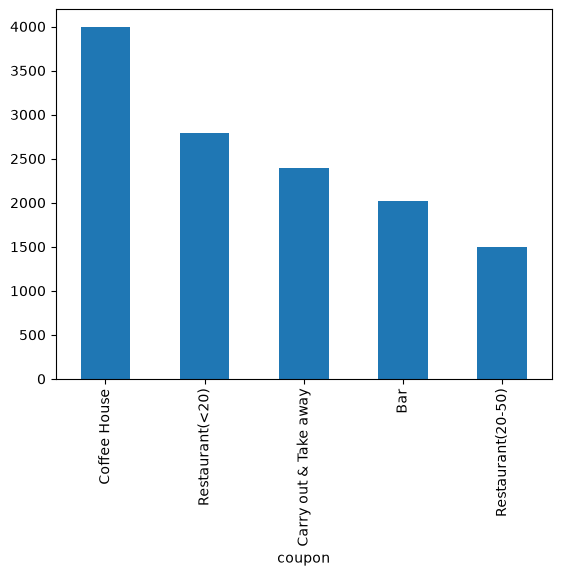

In [7]:
data["coupon"].value_counts().plot(kind="bar")

6. Use a histogram to visualize the temperature column.

<Axes: ylabel='Frequency'>

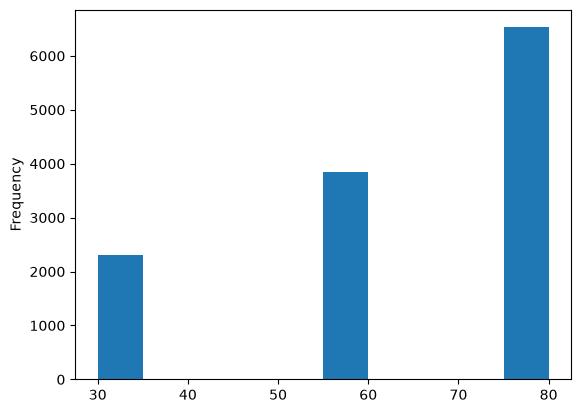

In [8]:
data["temperature"].plot(kind="hist")
# data["temperature"].value_counts()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [9]:
data_bar_only = data[data["coupon"] == "Bar"]
data_bar_only.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1


2. What proportion of bar coupons were accepted?


In [10]:
acceptance_rate_bar_only = get_acceptance_rate(data_bar_only)
print(f"{acceptance_rate_bar_only:.2f}% acceptance rate - people who received the bar coupon")

41.00% acceptance rate - people who received the bar coupon


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [11]:
# data_bar_only["Bar"].value_counts()
data_bar_only["bar_3"] = data_bar_only["Bar"].map({
    "never": "≤3",
    "less1": "≤3",
    "1~3": "≤3",
    "4~8": ">3",
    "gt8": ">3"
})
data_bar_only["bar_3"].value_counts()

bar_3
≤3    1797
>3     199
Name: count, dtype: int64

In [12]:
acceptance_rate_bar_only_3less = get_acceptance_rate(data_bar_only[data_bar_only["bar_3"] == "≤3"])
print(f"{acceptance_rate_bar_only_3less:.2f}% acceptance rate - went to a bar 3 or fewer times a month.")

acceptance_rate_bar_only_3more = get_acceptance_rate(data_bar_only[data_bar_only["bar_3"] == ">3"])
print(f"{acceptance_rate_bar_only_3more:.2f}% acceptance rate - went to a bar more than 3 times a month.")

37.06% acceptance rate - went to a bar 3 or fewer times a month.
76.88% acceptance rate - went to a bar more than 3 times a month.


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [13]:
acceptance_rate_bar_only_over1_over25yo = get_acceptance_rate(
    data_bar_only[
        ~data_bar_only["Bar"].isin(["never", "less1"]) & 
        data_bar_only["age"].isin(["26", "31", "36", "41", "46", "50plus"])
    ]
)
print(f"{acceptance_rate_bar_only_over1_over25yo:.2f}% acceptance rate - went to a bar more than 1 time per month and over 25yo.")

acceptance_rate_bar_only_NOT_over1_over25yo = get_acceptance_rate(
    data_bar_only[
        data_bar_only["Bar"].isin(["never", "less1"]) & 
        ~data_bar_only["age"].isin(["26", "31", "36", "41", "46", "50plus"])
    ]
)
print(f"{acceptance_rate_bar_only_NOT_over1_over25yo:.2f}% acceptance rate - went to a bar less than once per month and under 25yo.")
# data_bar_only["age"].value_counts()

68.18% acceptance rate - went to a bar more than 1 time per month and over 25yo.
39.45% acceptance rate - went to a bar less than once per month and under 25yo.


The cohort going to bars more frequently and are in the bar visiting age group are much more likely to acccept a bar coupon.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [14]:
acceptance_rate_bar_only_barOver1_noKids_occupation = get_acceptance_rate(
    data_bar_only[
        (~data_bar_only["Bar"].isin(["never", "less1"])) & 
        (~data_bar_only["passanger"].isin(["Kid(s)"])) &
        (~data_bar_only["occupation"].isin(["Farming Fishing & Forestry"]))
    ]
)
print(f"{acceptance_rate_bar_only_barOver1_noKids_occupation:.2f}% acceptance rate - went to a bar >1/month, no kid passengers, not in Farming Fishing & Forestry occupation.")

70.30% acceptance rate - went to a bar >1/month, no kid passengers, not in Farming Fishing & Forestry occupation.


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [ ]:
acceptance_rate_bar_only_barOver1_noKids_notWidowed = get_acceptance_rate(
    data_bar_only[
        (~data_bar_only["Bar"].isin(["never", "less1"])) & 
        (~data_bar_only["passanger"].isin(["Kid(s)"])) &
        (~data_bar_only["maritalStatus"].isin(["Widowed"]))
    ]
)
acceptance_rate_bar_only_barOver1_under30yo = get_acceptance_rate(
    data_bar_only[
        (~data_bar_only["Bar"].isin(["never", "less1"])) & 
        (data_bar_only["age"].isin(["below21", "21", "26"]))
    ]
)
acceptance_rate_bar_only_cheapOver4x_incomeLess50 = get_acceptance_rate(
    data_bar_only[
        (~data_bar_only["Bar"].isin(["never", "less1"])) & 
        (data_bar_only["RestaurantLessThan20"].isin(["4~8", "gt8"])) &
        (data_bar_only["income"].isin(["Less than $12500", "$12500 - $24999", "$25000 - $37499", "$37500 - $49999"]))
    ]
)

print(f"{acceptance_rate_bar_only_barOver1_noKids_notWidowed:.2f}% acceptance rate - went to a bar >1/month, no kid passengers, not widowed.")
print(f"{acceptance_rate_bar_only_barOver1_under30yo:.2f}% acceptance rate - went to a bar >1/month, under 30yo.")
print(f"{acceptance_rate_bar_only_cheapOver4x_incomeLess50:.2f}% acceptance rate - cheap restaurants >4/month, income less than 50k.")

70.30% acceptance rate - went to a bar >1/month, no kid passengers, not widowed.
72.21% acceptance rate - went to a bar >1/month, under 30yo.
74.81% acceptance rate - cheap restaurants >4/month, income less than 50k.


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Based on the defined observations, we can deduce that typical people who accept bar coupons are more frequent bar goers, drive without kids, and have an income that is less than 50K. However, this does not tell the full story as, for example, if we change the income filter to be >$50K, then we still get a 60% acceptance rate on the coupon. So while bar coupon acceptors do appear to be in the majority in the under $50K cohort, many over that threshold still do accept the coupon.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

<Axes: title={'center': 'Distribution of All Coupons'}, xlabel='coupon'>

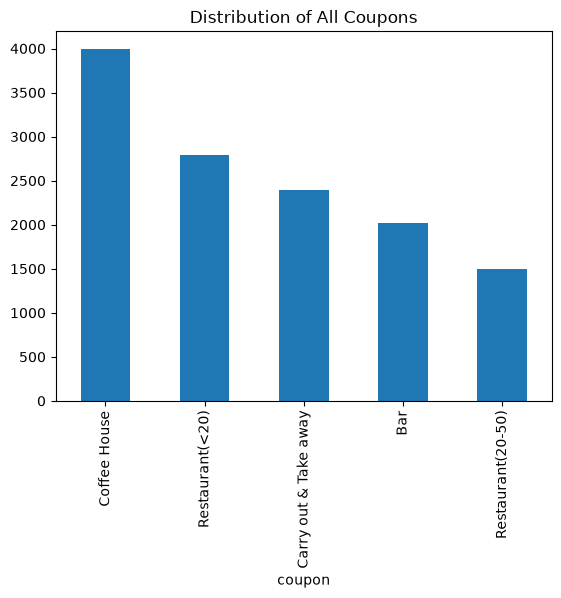

In [28]:
# Plot the distribution of all coupons
data["coupon"].value_counts().plot(kind="bar", title="Distribution of All Coupons")


<Axes: title={'center': 'Distribution of Accepted Coupons'}, xlabel='coupon'>

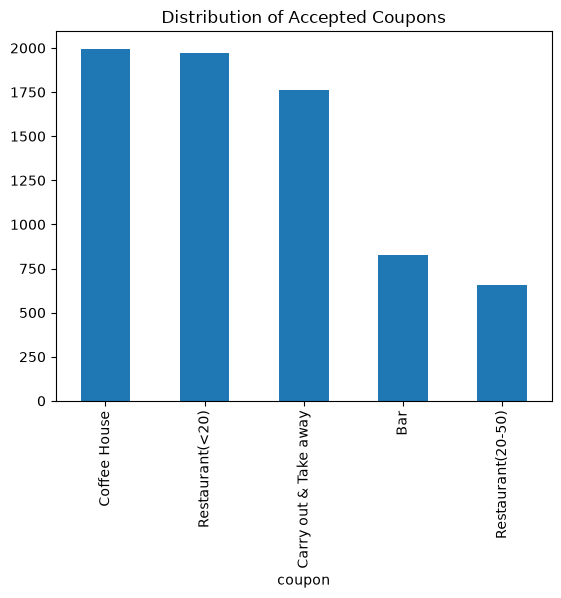

In [27]:
# Plot the distribution of accepted coupons
data_accepted = data[data["Y"] == 1]
data_accepted["coupon"].value_counts().plot(kind="bar", title="Distribution of Accepted Coupons")

<Axes: title={'center': 'Distribution of Coupons by Acceptance Status'}, xlabel='coupon,Y'>

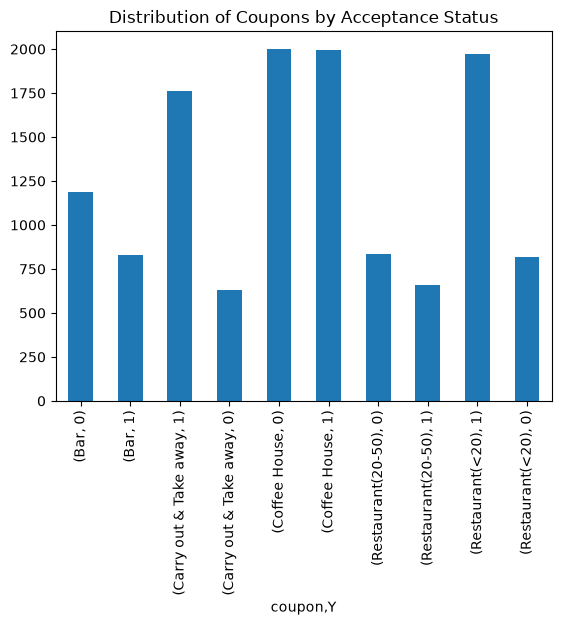

In [29]:
# Plot the distribution of coupons by acceptance status
dd = data.groupby("coupon")["Y"].value_counts()
dd.plot(kind="bar", x="coupon", title="Distribution of Coupons by Acceptance Status")

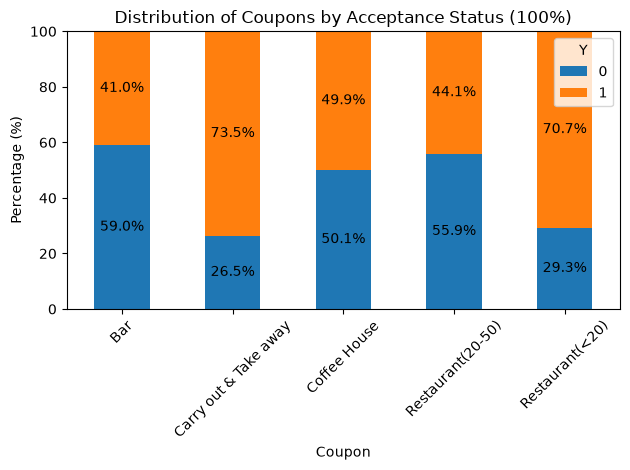

In [ ]:
# Plot the distribution of coupons by acceptance status as 100% stacked bar chart
coupon_acceptance_rate = pd.crosstab(data["coupon"], data["Y"], normalize="index") * 100
plotted = coupon_acceptance_rate.plot(
    kind="bar",
    stacked=True,
    title="Distribution of Coupons by Acceptance Status (100%)",
)

for container in plotted.containers:
    plotted.bar_label(container, fmt="%.1f%%", label_type="center")

plt.xlabel("Coupon")
plt.ylabel("Percentage (%)")
plt.legend(title="Y")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

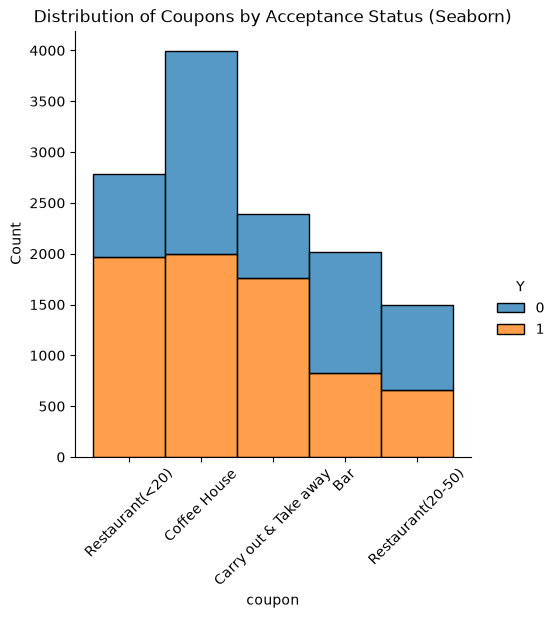

In [32]:
# Seaborn stacked histogram of coupons by acceptance status
sns.displot(data=data, x="coupon", hue="Y", multiple="stack")
plt.title("Distribution of Coupons by Acceptance Status (Seaborn)")
plt.xticks(rotation=45)
plt.show()

<Axes: title={'center': 'Distribution of Age for Top 3 Coupons'}, xlabel='age'>

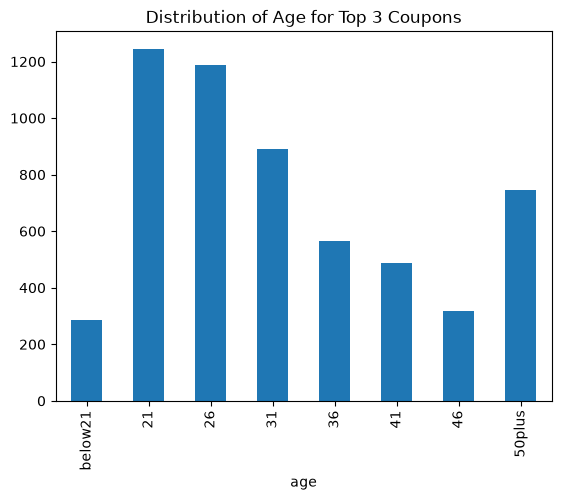

In [ ]:
# Create a new DataFrame containing only the top 3 coupons
data_top_3 = data[
    data["coupon"].isin(["Coffee House", "Carry out & Take away", "Restaurant(<20)"])
    & data["Y"]
    == 1
]

# Plot the distribution of age for the top 3 coupons
age_order = ["below21", "21", "26", "31", "36", "41", "46", "50plus"]
data_top_3["age"].value_counts().reindex(age_order).plot(
    kind="bar", title="Distribution of Age for Top 3 Coupons"
)

<Axes: title={'center': 'Distribution of Passengers for Top 3 Coupons'}, xlabel='passanger'>

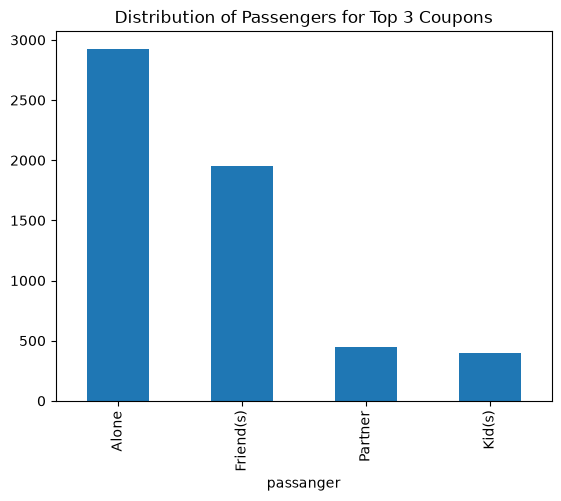

In [ ]:
# Plot the distribution of passengers for the top 3 coupons
data_top_3["passanger"].value_counts().plot(
    kind="bar", title="Distribution of Passengers for Top 3 Coupons"
)

<Axes: title={'center': 'Distribution of Occupation for Top 3 Coupons'}, xlabel='occupation'>

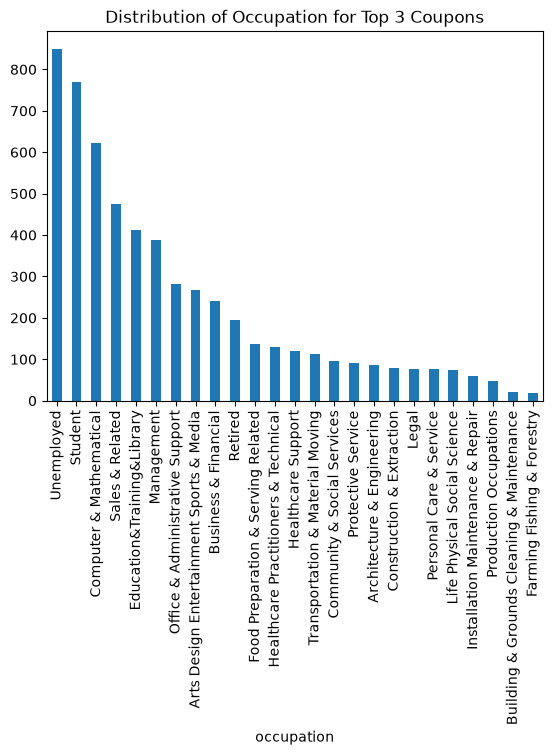

In [ ]:
# Plot the distribution of occupation for the top 3 coupons
data_top_3["occupation"].value_counts().plot(
    kind="bar", title="Distribution of Occupation for Top 3 Coupons"
)

<Axes: title={'center': 'Distribution of Destination for Top 3 Coupons'}, xlabel='destination'>

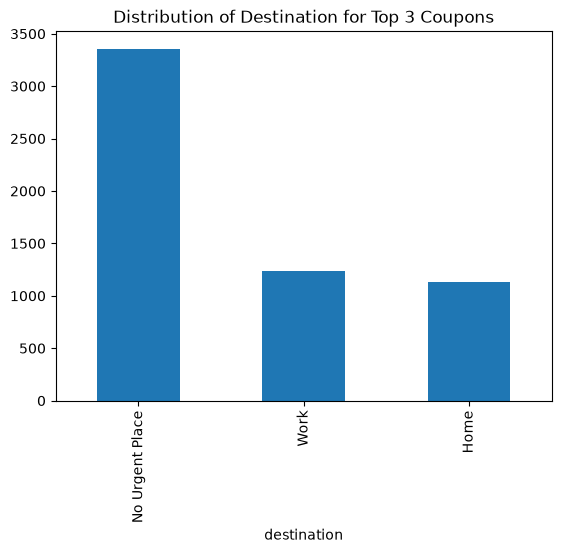

In [ ]:
# Plot the distribution of destination for the top 3 coupons
data_top_3["destination"].value_counts().plot(
    kind="bar", title="Distribution of Destination for Top 3 Coupons"
)

<Axes: title={'center': 'Distribution of Marital Status for Top 3 Coupons'}, xlabel='maritalStatus'>

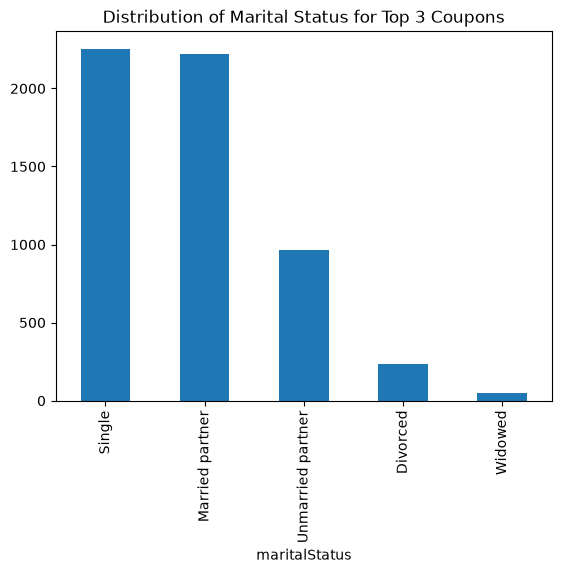

In [ ]:
# Plot the distribution of marital status for the top 3 coupons
data_top_3["maritalStatus"].value_counts().plot(
    kind="bar", title="Distribution of Marital Status for Top 3 Coupons"
)

Text(50.385633680555536, 0.5, 'Coupon Type')

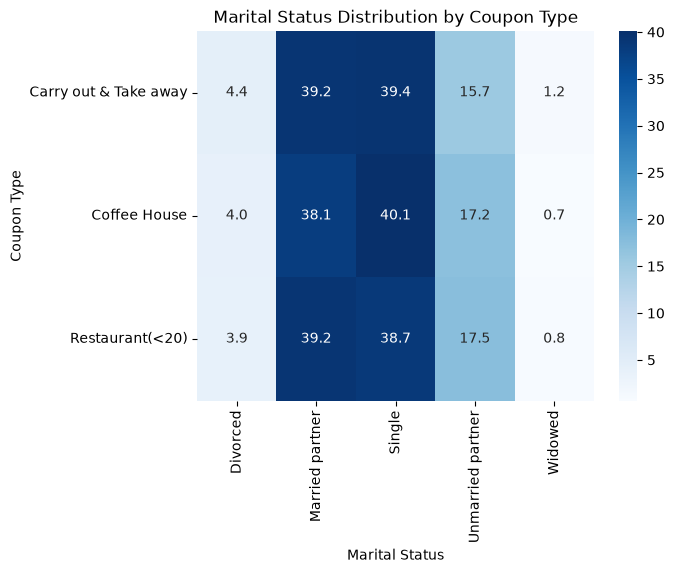

In [ ]:
coupon_marital = (
    pd.crosstab(data_top_3["coupon"], data_top_3["maritalStatus"], normalize="index")
    * 100
)

sns.heatmap(coupon_marital, annot=True, fmt=".1f", cmap="Blues")

plt.title("Marital Status Distribution by Coupon Type")
plt.xlabel("Marital Status")
plt.ylabel("Coupon Type")

<Axes: title={'center': 'Acceptance Rate for Coffee House Coupon (Filtered)'}, xlabel='Y'>

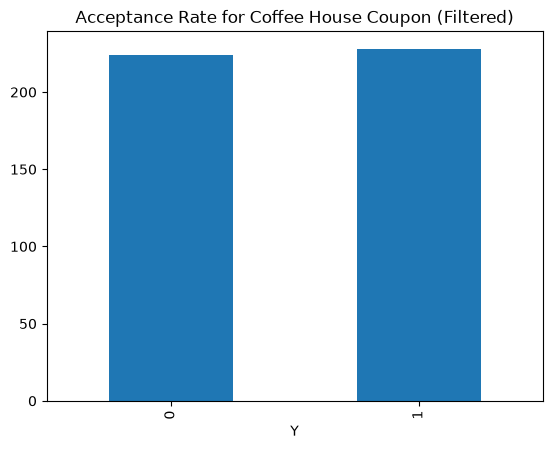

In [44]:
data_coffee_only = data[data["coupon"] == "Coffee House"]
data_coffee_only_filtered = data_coffee_only[
    (data_coffee_only["occupation"].isin(["Unemployed", "Student"])) &
    (data_coffee_only["passanger"].isin(["Alone"])) &
    (data_coffee_only["age"].isin(["21", "26", "31"]))
]
data_coffee_only_filtered.groupby("Y").size().plot(kind="bar", title="Acceptance Rate for Coffee House Coupon (Filtered)")

In [45]:
acceptance_rate_coffee_5min = get_acceptance_rate(
    data_coffee_only_filtered[
        (data_coffee_only_filtered["toCoupon_GEQ5min"] == 1)]
)
acceptance_rate_coffee_15min = get_acceptance_rate(
    data_coffee_only_filtered[
        (data_coffee_only_filtered["toCoupon_GEQ15min"] == 1)]
)
acceptance_rate_coffee_25min = get_acceptance_rate(
    data_coffee_only_filtered[
        (data_coffee_only_filtered["toCoupon_GEQ25min"] == 1)]
)
print(f"{acceptance_rate_coffee_5min:.2f}% acceptance rate - went to a bar >1/month, no kid passengers, not widowed.")
print(f"{acceptance_rate_coffee_15min:.2f}% acceptance rate - went to a bar >1/month, under 30yo.")
print(f"{acceptance_rate_coffee_25min:.2f}% acceptance rate - cheap restaurants >4/month, income less than 50k.")

50.44% acceptance rate - went to a bar >1/month, no kid passengers, not widowed.
47.88% acceptance rate - went to a bar >1/month, under 30yo.
46.67% acceptance rate - cheap restaurants >4/month, income less than 50k.


It seems the primary acceptors of the coffee house coupon are students in the age ranges of 21-36, are unmarried, and typically drive alone or with friends. For this cohort, it is also not an issue if the coffee house is up to 25 minutes away, as distance does not play a huge factor in acceptance. Another interesting tidbit of this cohort is that those who accepted were most likely driving with no urgent destination in mind.